In [1]:
import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv('spam.csv', encoding='latin-1')

In [3]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
df.shape

(5572, 5)

# 1.  Data Cleaning
# 2.  EDA
# 3.  Text Preprocessing
# 4.  Model buidling
# 5.  Evaluation
# 6.  Improvement
# 7.  Websit
# 8. Deploy
 

## 1. Data Cleaning

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
# drop last 3 columns

df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True)

In [7]:
# rename the columns

df.columns = ['label', 'messages']


In [8]:
df.columns

Index(['label', 'messages'], dtype='object')

In [9]:
from sklearn.preprocessing import LabelEncoder

In [10]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])

In [11]:
df.head()

,label,messages
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [12]:
# missing Values 
df.isnull().sum()

label       0
messages    0
dtype: int64

In [13]:
# Check for duplicated values

df.duplicated().sum()

np.int64(403)

In [14]:
# Remove duplicates

df = df.drop_duplicates(keep='first')

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.shape

(5169, 2)

## 2. EDA

In [17]:
df['label'].value_counts()

label
0    4516
1     653
Name: count, dtype: int64

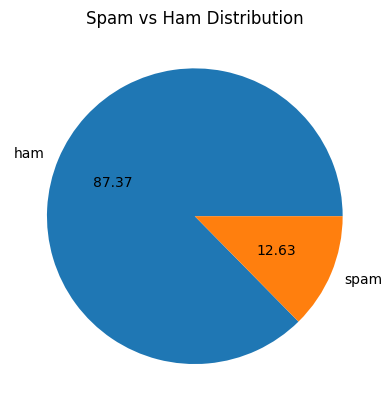

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = ['ham', 'spam']
sizes = [4516, 653]
plt.pie(sizes, labels=labels, autopct='%.2f')
plt.title("Spam vs Ham Distribution")
plt.show()

In [19]:
# Data is Imbalaced ..

In [20]:
import nltk

In [21]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /Users/saiqa/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [22]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /Users/saiqa/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [23]:
df['num_characters'] = df['messages'].apply(len)

In [24]:
df.head()

,label,messages,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [25]:
# num of words 

from nltk.tokenize import word_tokenize



In [26]:
df['num_words'] = df['messages'].apply(lambda x: len(nltk.word_tokenize(x)))

In [27]:
df.head()

,label,messages,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [28]:
df['num_sentences'] = df['messages'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [29]:
df.head()

,label,messages,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [30]:
df[['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [31]:
# this is for ham messages
df[df['label'] == 0][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [32]:
# for spam
df[df['label'] == 1][['num_characters', 'num_words', 'num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [33]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

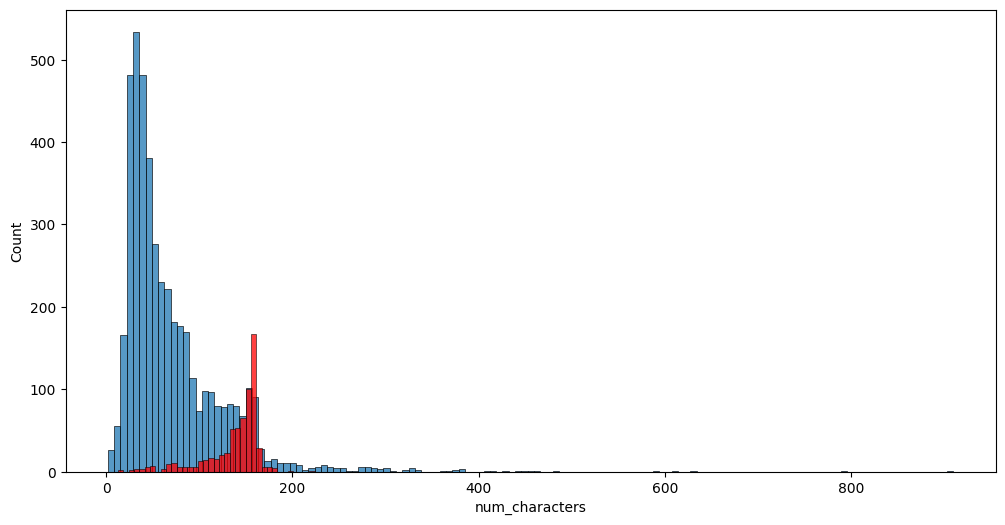

In [34]:
plt.figure(figsize=(12, 6))
sns.histplot(df[df['label']==0]['num_characters'])
sns.histplot(df[df['label']==1]['num_characters'], color='red')

<Axes: xlabel='num_words', ylabel='Count'>

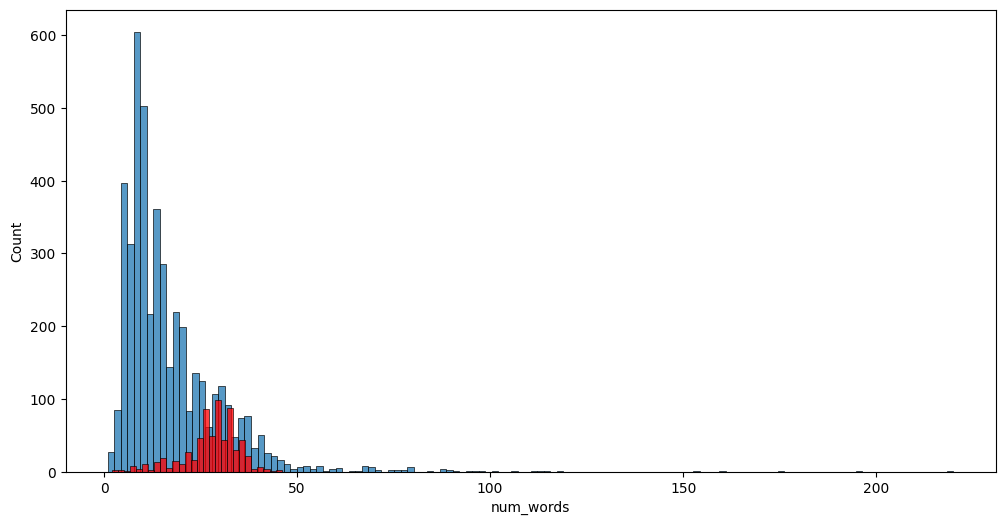

In [35]:
plt.figure(figsize=(12, 6))
sns.histplot(df[df['label']==0]['num_words'])
sns.histplot(df[df['label']==1]['num_words'], color='red')

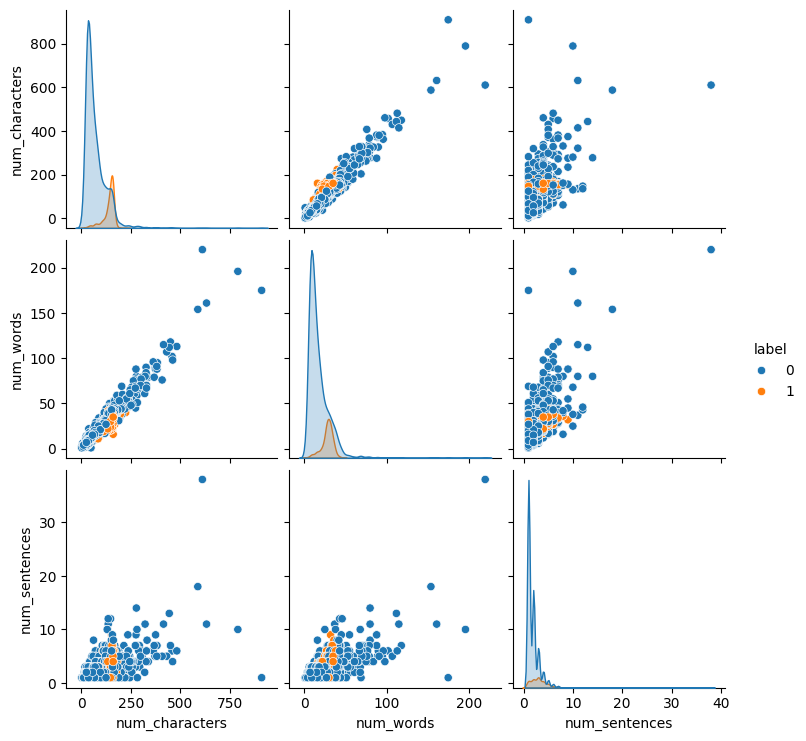

In [36]:
sns.pairplot(df, hue='label')

<Axes: >

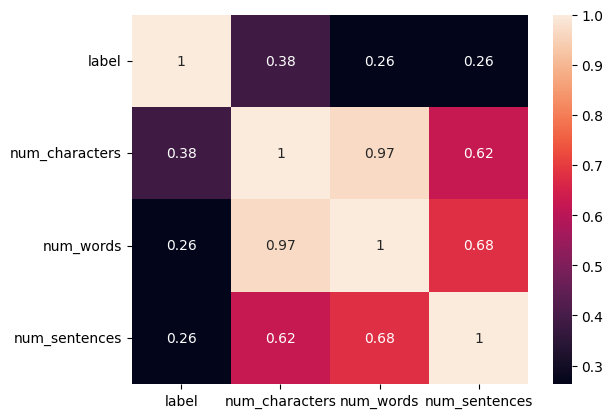

In [37]:
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True)


# 3. Data Preprocessing 
     . Lower case
     . Tokenization
     . Removing Special characters
     . Removing Stop words and punctuations
     . Stemming

In [38]:
import string
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()

In [42]:
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

ps = PorterStemmer()
stop_words = set(stopwords.words('english'))  # define once

def transform_text(text):

    # 1️⃣ Lowercase
    text = text.lower()

    # 2️⃣ Tokenize
    text = nltk.word_tokenize(text)

    # 3️⃣ Remove special characters (keep alphanumeric)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)

    # 4️⃣ Remove stopwords
    text = []
    for i in y:   # ✅ now looping over cleaned words
        if i not in stop_words:
            text.append(i)

    # 5️⃣ Stemming
    y = []
    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)


In [43]:
transform_text('Hello, World!')

'hello world'

In [45]:
df['transformed_messages'] = df['messages'].apply(transform_text)

In [46]:
 df.head()

,label,messages,num_characters,num_words,num_sentences,transformed_messages
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [47]:
from wordcloud import WordCloud
wc =  WordCloud(
    width=500,
    height=500,
    min_font_size = 10,
    background_color='white'
)


In [48]:
spam_wc = wc.generate(df[df['label'] == 1]['transformed_messages'].str.cat(sep=" "))

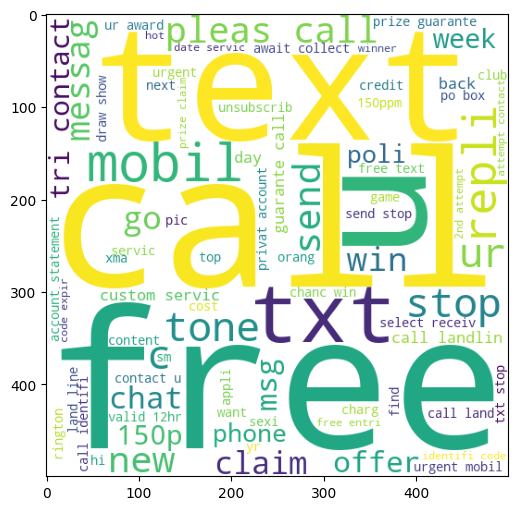

In [49]:
plt.figure(figsize=(12, 6))
plt.imshow(spam_wc)

In [50]:
ham_wc = wc.generate(df[df['label'] == 0]['transformed_messages'].str.cat(sep=" "))

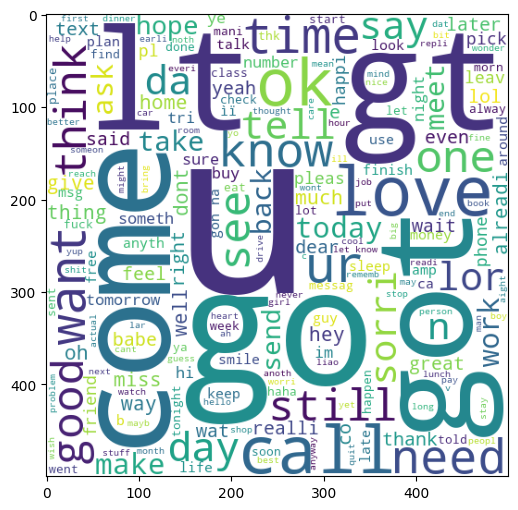

In [51]:
plt.figure(figsize=(12, 6))
plt.imshow(ham_wc)

In [52]:
spam_corrups = []
for msg in df[df['label'] == 1]['transformed_messages'].tolist():
    for word in msg.split():
        spam_corrups.append(word)

In [54]:
len(spam_corrups)

9939

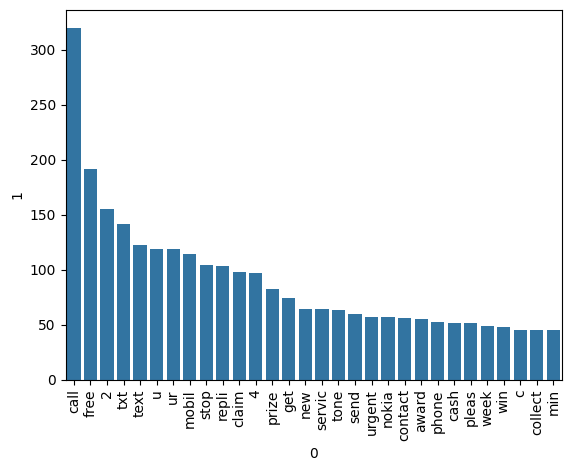

In [62]:
from collections import Counter
sns.barplot(
    x = pd.DataFrame(Counter(spam_corrups).most_common(30))[0],
    y =  pd.DataFrame(Counter(spam_corrups).most_common(30))[1]
)

plt.xticks(rotation='vertical')
plt.show()

In [66]:
ham_corrups = []
for msg in df[df['label'] == 0]['transformed_messages'].tolist():
    for word in msg.split():
        ham_corrups.append(word)

In [67]:
len(ham_corrups)

35404

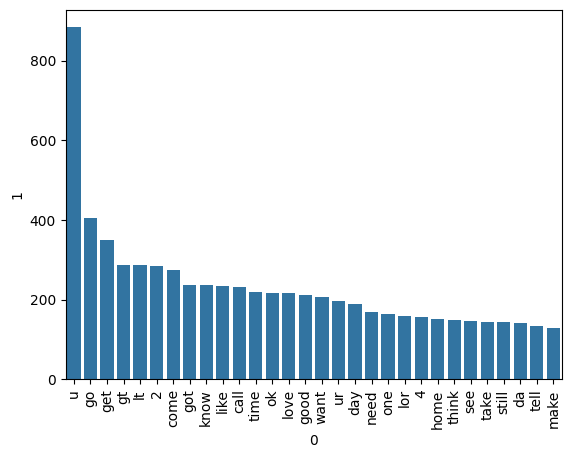

In [68]:
from collections import Counter
sns.barplot(
    x = pd.DataFrame(Counter(ham_corrups).most_common(30))[0],
    y =  pd.DataFrame(Counter(ham_corrups).most_common(30))[1]
)

plt.xticks(rotation='vertical')
plt.show()

# 4. Model Building

In [169]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

In [170]:
X = tfidf.fit_transform(df['transformed_messages']).toarray()

In [171]:
X.shape

(5169, 3000)

In [172]:
y = df['label'].values

In [173]:
y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

In [174]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, recall_score

In [175]:
X_train, X_test, y_train, y_test = train_test_split(
...     X, y, test_size=0.2, random_state=2)

In [176]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

In [177]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [178]:
gnb.fit(X_train, y_train)
y_pred1 = gnb.predict(X_test)


In [179]:
print('accuracy_score:',accuracy_score(y_test, y_pred1))
print('precision_score:',precision_score(y_test, y_pred1))
print('recall_score:',recall_score(y_test, y_pred1))
print('confusion_matrix:\n',confusion_matrix(y_test, y_pred1))

accuracy_score: 0.8694390715667312
precision_score: 0.5068493150684932
recall_score: 0.8043478260869565
confusion_matrix:
 [[788 108]
 [ 27 111]]


In [180]:
mnb.fit(X_train, y_train)
y_pred2 = mnb.predict(X_test)


In [181]:
print('accuracy_score:',accuracy_score(y_test, y_pred2))
print('precision_score:',precision_score(y_test, y_pred2))
print('recall_score:',recall_score(y_test, y_pred2))
print('confusion_matrix:\n',confusion_matrix(y_test, y_pred2))

accuracy_score: 0.9709864603481625
precision_score: 1.0
recall_score: 0.782608695652174
confusion_matrix:
 [[896   0]
 [ 30 108]]


In [182]:
bnb.fit(X_train, y_train)
y_pred3 = bnb.predict(X_test)

In [183]:

print('accuracy_score:',accuracy_score(y_test, y_pred3))
print('precision_score:',precision_score(y_test, y_pred3))
print('recall_score:',recall_score(y_test, y_pred3))
print('confusion_matrix:\n',confusion_matrix(y_test, y_pred3))

accuracy_score: 0.9835589941972921
precision_score: 0.991869918699187
recall_score: 0.8840579710144928
confusion_matrix:
 [[895   1]
 [ 16 122]]


In [184]:
import joblib

# Save the trained model
joblib.dump(mnb, 'model.pkl')


['model.pkl']

In [185]:
joblib.dump(tfidf, 'vectorizer.pkl')

['vectorizer.pkl']